
1	Project overview aur library imports

2	Dataset load aur inspect

3	Missing values, duplicates aur sentiment labels check

4	Text cleaning: lowercase, HTML, punctuation aur stopwords

5	Tokenization aur lemmatization/stemming

6	Train-test split

7	TF-IDF vectorization (max_features=5000)

8	Multinomial Naive Bayes aur Logistic Regression train karna

9	Accuracy aur classification metrics compare karna

10	Confusion matrix aur model comparison

11	predict_sentiment() interactive function banana

12	Conclusion, README, final verification aur GitHub submission


# Task 4: NLP Sentiment Classification on Customer Reviews

## 1. Project Overview

The goal of this project is to build a Natural Language
Processing (NLP) classifier that predicts whether a review
expresses positive or negative sentiment.

We will preprocess raw review text, transform it into
numerical TF-IDF features, and train classification models.

## Project Objectives

1. Load and inspect the sentiment review dataset.
2. Check missing values, duplicate records, and sentiment labels.
3. Clean text by removing HTML tags, punctuation, and unnecessary
   whitespace, and by converting text to lowercase.
4. Tokenize the text and apply stopword removal and lemmatization
   or stemming.
5. Split the dataset into training and testing sets.
6. Convert text into numerical TF-IDF vectors with a maximum
   of 5,000 features.
7. Train and compare Multinomial Naive Bayes and Logistic Regression.
8. Evaluate model accuracy and classification performance.
9. Create a predict_sentiment() function for custom user reviews.

## Expected Outcome

A documented Jupyter Notebook containing the text preprocessing
pipeline, TF-IDF features, trained classifiers, evaluation
metrics, and an interactive sentiment prediction function.

## 2. Import Required Libraries

We will use Pandas and NumPy for data handling, regular
expressions for cleaning text, and Matplotlib and Seaborn
for visualizations.

Scikit-learn will provide TF-IDF vectorization, classification
models, and evaluation metrics. Text-processing libraries
will be added when required.

In [1]:
# Import libraries for data handling and text preprocessing

import pandas as pd
import numpy as np
import re

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Use a consistent visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Load and Inspect the Sentiment Dataset

We load the review dataset using Pandas and inspect its
structure, columns, missing values, duplicate records,
and sentiment distribution.

This helps us understand the available text data and
identify any issues before preprocessing and modelling.

In [2]:
# Load the review dataset
df = pd.read_csv("sentiment_reviews.csv")

# Inspect dataset structure
print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

# Check missing values and duplicates
print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Check sentiment distribution
print("\nSentiment distribution:")
display(df["sentiment"].value_counts().to_frame(name="Count"))

Dataset shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative



Column names:
['review_id', 'review_text', 'sentiment']

Missing values:


review_id      0
review_text    0
sentiment      0
dtype: int64


Duplicate rows: 0

Sentiment distribution:


,Count
sentiment,
positive,5
negative,4
neutral,1


## 3. Load and Inspect the Sentiment Reviews Dataset

We use the provided sentiment_reviews.csv file for this project.

The dataset contains review text and sentiment labels.
We will inspect the data before cleaning and preprocessing.

The classification task focuses on positive and negative
sentiment. Any neutral review will be handled explicitly
before binary model training.

In [3]:
# Load the provided sentiment review dataset
df = pd.read_csv("sentiment_reviews.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)
display(df.head())

print("\nSentiment distribution:")
display(df["sentiment"].value_counts().to_frame(name="Count"))

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative



Sentiment distribution:


,Count
sentiment,
positive,5
negative,4
neutral,1



Missing values:


review_id      0
review_text    0
sentiment      0
dtype: int64

## 4. Text Preprocessing

Raw customer reviews may contain uppercase letters, HTML tags,
punctuation, and common words that are not useful for sentiment
classification.

We will:
- Keep only positive and negative reviews for binary classification.
- Convert text to lowercase.
- Remove HTML tags and punctuation.
- Tokenize text into individual words.
- Remove common English stopwords while preserving negation words
  such as "no", "not", and "nor".
- Apply lemmatization to reduce words to their base form.

We will preserve the original review text and store the cleaned
text in a separate column.

In [4]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Import tools for text preprocessing
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download the language resources required for preprocessing
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Keep only positive and negative reviews
df_binary = df[
    df["sentiment"].isin(["positive", "negative"])
].copy()

print("Reviews before filtering:", len(df))
print("Reviews for binary classification:", len(df_binary))

# Prepare stopwords, preserving important negations
stop_words = set(stopwords.words("english"))
stop_words -= {"no", "not", "nor"}

lemmatizer = WordNetLemmatizer()


def clean_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize text into words
    tokens = text.split()

    # Remove stopwords and apply lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    # Join the cleaned words into a sentence
    return " ".join(tokens)


# Create a cleaned-text column
df_binary["cleaned_text"] = df_binary["review_text"].apply(clean_text)

# Inspect the results
display(df_binary[["review_text", "cleaned_text", "sentiment"]])

Reviews before filtering: 10
Reviews for binary classification: 9


,review_text,cleaned_text,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...,positive
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


## 5. Split the Dataset into Training and Testing Sets

We use the cleaned positive and negative reviews for binary
sentiment classification.

The review text is the input feature, and sentiment is the
target variable. We split the data into training and testing
sets while preserving the class proportions using stratification.

The TF-IDF vectorizer will be fitted on training text only
to prevent data leakage.

In [6]:
# Import the train-test split function
from sklearn.model_selection import train_test_split

# Keep non-empty cleaned reviews
df_model = df_binary[
    df_binary["cleaned_text"].str.strip().ne("")
].copy()

# Separate input text and target labels
X = df_model["cleaned_text"]
y = df_model["sentiment"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check dataset sizes and class distribution
print("Total reviews:", len(df_model))
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment distribution:")
display(y_train.value_counts().to_frame(name="Count"))

print("\nTesting sentiment distribution:")
display(y_test.value_counts().to_frame(name="Count"))

Total reviews: 9
Training reviews: 7
Testing reviews: 2

Training sentiment distribution:


,Count
sentiment,
positive,4
negative,3



Testing sentiment distribution:


,Count
sentiment,
negative,1
positive,1


## 6. Convert Text into TF-IDF Features

Machine-learning models require numerical input rather than
raw text.

We use TfidfVectorizer to convert cleaned reviews into
numerical feature vectors.

TF-IDF gives importance to words based on their frequency
within a review and how informative they are across reviews.

We set max_features=5000 as specified in the assignment.

The vectorizer is fitted only on training text and then
used to transform both training and testing text, preventing
data leakage.

In [7]:
# Import the TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Learn vocabulary and transform training reviews
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing reviews using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Inspect the resulting feature matrices
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (7, 46)
Testing TF-IDF shape: (2, 46)
Vocabulary size: 46


## 7. Train Sentiment Classification Models

We will train and compare two text classification models:

- Multinomial Naive Bayes: A probabilistic classifier commonly
  used with word-count and TF-IDF text features.
- Logistic Regression: A linear classifier that learns to
  distinguish positive and negative sentiment.

Both models will use the same TF-IDF training features.
We will evaluate their predictions on the held-out test set
using accuracy, precision, recall, and F1-score.

Because the dataset is very small, the resulting metrics
are for demonstration only and should not be treated as
reliable estimates of real-world performance.

In [8]:
# Import classification models and evaluation metrics
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create the two classification models
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

# Store predictions and evaluation results
predictions = {}
results = []

# Train and evaluate each model
for model_name, model in models.items():

    # Train using TF-IDF training features
    model.fit(X_train_tfidf, y_train)

    # Predict sentiment for test reviews
    y_pred = model.predict(X_test_tfidf)
    predictions[model_name] = y_pred

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="positive",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label="positive",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred,
            pos_label="positive",
            zero_division=0
        )
    })

    print(f"\n{model_name} — Classification Report")
    print(classification_report(
        y_test,
        y_pred,
        labels=["negative", "positive"],
        zero_division=0
    ))

# Display the comparison table
results_df = pd.DataFrame(results).sort_values(
    "Accuracy",
    ascending=False
)

print("\nModel Comparison:")
display(results_df.round(3))


Multinomial Naive Bayes — Classification Report
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


Logistic Regression — Classification Report
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.5,0.5,1.0,0.667
1,Logistic Regression,0.5,0.5,1.0,0.667


## 8. Confusion Matrix

A confusion matrix compares the actual sentiment labels with
the model's predicted labels.

It shows how many positive and negative reviews were classified
correctly and how many were misclassified.

We will compare the results of Multinomial Naive Bayes and
Logistic Regression using the held-out test set.

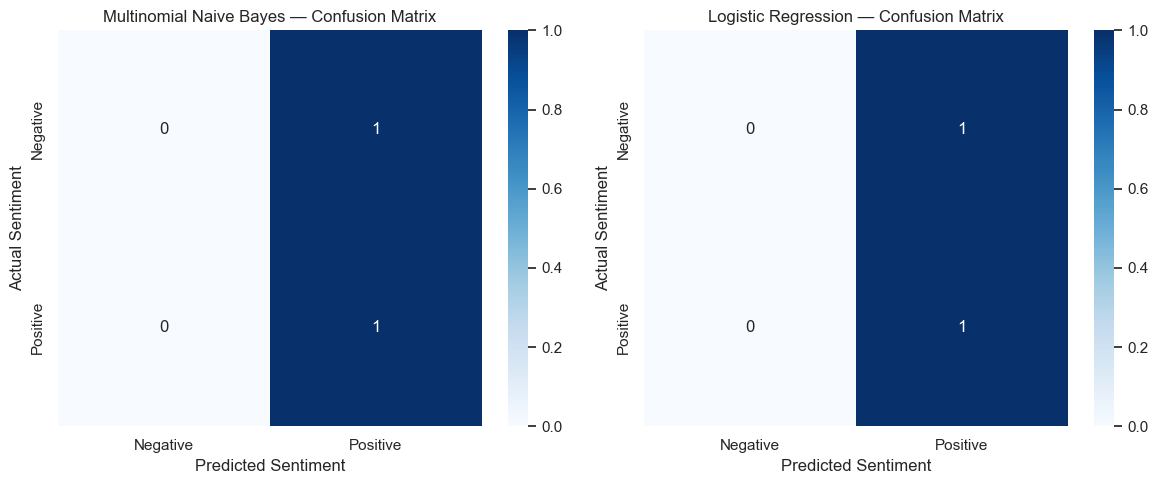

In [9]:
# Import the confusion matrix function
from sklearn.metrics import confusion_matrix

# Create side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["negative", "positive"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

## 9. Interactive Sentiment Prediction

We create a `predict_sentiment()` function that accepts
a new review typed by the user.

The function cleans the input using the same preprocessing
steps used during training, transforms it with the fitted
TF-IDF vectorizer, and predicts sentiment using both models.

This allows us to test custom review phrases interactively.

In [10]:
# Predict sentiment for a custom user review
def predict_sentiment(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty review.")

    # Apply the same text cleaning used during training
    cleaned_review = clean_text(text)

    if not cleaned_review.strip():
        raise ValueError("The review contains no usable words after cleaning.")

    # Transform using the TF-IDF vocabulary learned during training
    review_tfidf = tfidf.transform([cleaned_review])

    # Get a prediction from each trained model
    predictions_for_review = {}

    for model_name, model in models.items():
        prediction = model.predict(review_tfidf)[0]
        predictions_for_review[model_name] = prediction

    return predictions_for_review


# Test the function with custom review phrases
test_reviews = [
    "This product is excellent and easy to use!",
    "Terrible quality and very disappointing service."
]

for review in test_reviews:
    print("Review:", review)
    print("Predictions:", predict_sentiment(review))
    print("-" * 60)

Review: This product is excellent and easy to use!
Predictions: {'Multinomial Naive Bayes': np.str_('positive'), 'Logistic Regression': 'positive'}
------------------------------------------------------------
Review: Terrible quality and very disappointing service.
Predictions: {'Multinomial Naive Bayes': np.str_('positive'), 'Logistic Regression': 'positive'}
------------------------------------------------------------


## 10. Conclusion

This project demonstrates a basic NLP sentiment classification
pipeline using the provided customer review dataset.

The workflow included text cleaning, lowercasing, punctuation
removal, stopword filtering, lemmatization, TF-IDF vectorization,
and training Multinomial Naive Bayes and Logistic Regression.

Both models achieved 50% accuracy on the two-review test set.
Both classified the test reviews as positive, including one
negative review, showing that the models did not reliably
distinguish positive and negative sentiment.

The dataset contained only 10 reviews, of which 9 were positive
or negative and 1 was neutral. Therefore, the evaluation results
are for demonstration only and cannot be treated as reliable
performance estimates.

The project also implemented a predict_sentiment() function
for testing custom review text with both trained models.

A larger labelled dataset is required for meaningful evaluation
and more reliable sentiment predictions.